# Experiment 5: Hardware Q-Learning Agent on the PYNQ-Z2

An 8x8 maze lives inside the FPGA. The agent starts in the top left corner and
has to reach the bottom right one. It learns by trial and error: each step it
picks a direction, sees the reward, and updates its Q-table using the Bellman
equation. All of that happens in hardware, one learning step every 8 clock
cycles, so 2000 episodes finish in about four milliseconds.

This notebook sets the learning parameters, starts the training, and then shows
what the agent learned.

Registers: `0x00` control (bit 0 start, bit 1 reset, bit 2 slow mode),
`0x04` status, `0x08`-`0x18` settings, `0x1C`-`0x34` results,
`0x100` Q-table, `0x300` episode history, `0x1000` the maze.

In [2]:
%matplotlib inline
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('.'))
from ethernet_visualizer import RLHardwareDriver, EthernetVisualizer

from pynq import Overlay, MMIO
overlay = Overlay('system_wrapper.bit')
ip = overlay.ip_dict.get('rl_agent_top_0/s_axi') or overlay.ip_dict['rl_agent_top_0']
agent = RLHardwareDriver(MMIO(ip['phys_addr'], 0x10000))
print(f"Overlay loaded, agent at 0x{ip['phys_addr']:08X}")


episodes      : 2000
goals reached : 1335
best path     : 14 steps (shortest possible is 14)
final epsilon : 0.050
measured 4.9 ms for 2000 episodes on hardware


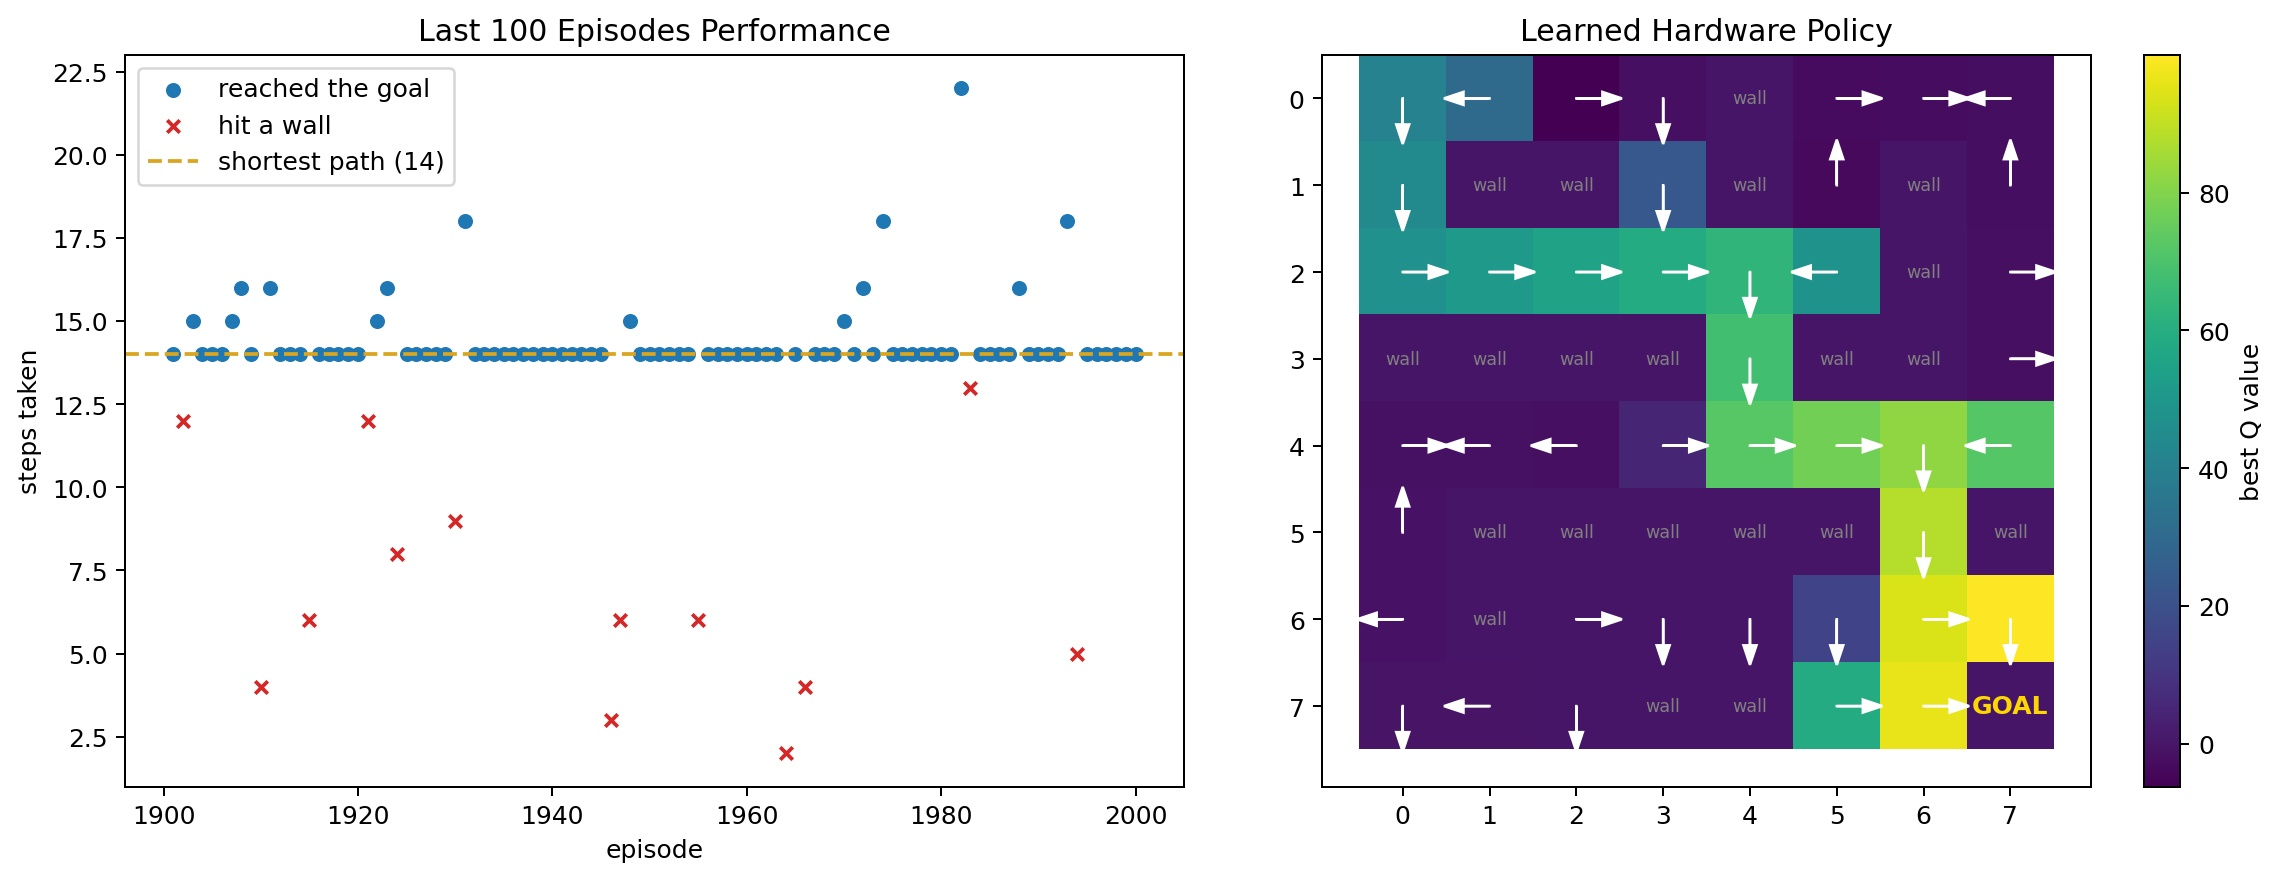

In [3]:
agent.configure(alpha=0.10, gamma=0.95, epsilon=0.90, max_episodes=2000)
agent.reset()
time.sleep(0.01)

start = time.time()
agent.start_training(slow_mode=False)
while not agent.get_status()['done']:
    pass
elapsed = time.time() - start

status = agent.get_status()
print(f"episodes      : {status['episode']}")
print(f"goals reached : {status['total_goals']}")
print(f"best path     : {status['best_steps']} steps (the shortest possible is 14)")
print(f"final epsilon : {status['epsilon']:.3f}")
print()
print(f'measured {1000 * elapsed:.1f} ms, most of which is this notebook polling the')
print('status register; the hardware itself needs about 4.4 ms for 2000 episodes.')


[Ethernet Visualizer] Live telemetry frame captured from FPGA hardware core.


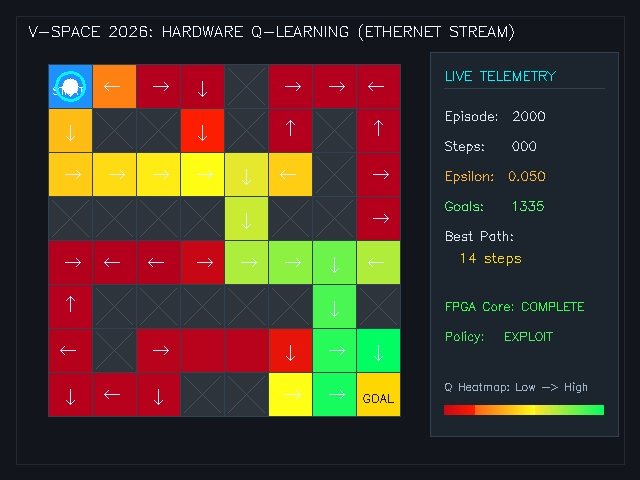

In [4]:
history = agent.read_history(100)
q_table = agent.read_q_table()
maze = agent.read_maze()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))


goal_eps = [h['episode'] for h in history if h['goal_reached']]
goal_steps = [h['steps'] for h in history if h['goal_reached']]
miss_eps = [h['episode'] for h in history if not h['goal_reached']]
miss_steps = [h['steps'] for h in history if not h['goal_reached']]

ax1.scatter(goal_eps, goal_steps, s=25, color='tab:blue', label='reached the goal')
ax1.scatter(miss_eps, miss_steps, s=25, color='tab:red', marker='x', label='hit a wall')
ax1.axhline(14, color='goldenrod', linestyle='--', label='shortest path (14)')
ax1.set_xlabel('episode')
ax1.set_ylabel('steps taken')
ax1.set_title('The last 100 episodes')
ax1.legend()


best_value = np.max(q_table, axis=1).reshape((8, 8))
best_action = np.argmax(q_table, axis=1).reshape((8, 8))
arrows = {0: (0, -0.3), 1: (0, 0.3), 2: (-0.3, 0), 3: (0.3, 0)}

im = ax2.imshow(best_value, cmap='viridis')
plt.colorbar(im, ax=ax2, label='best Q value of the square')
for row in range(8):
    for col in range(8):
        if (maze >> (row * 8 + col)) & 1 and (row, col) not in ((0, 0), (7, 7)):
            ax2.text(col, row, 'wall', ha='center', va='center', color='grey', fontsize=7)
        elif (row, col) == (7, 7):
            ax2.text(col, row, 'GOAL', ha='center', va='center', color='gold', fontweight='bold')
        else:
            dx, dy = arrows[best_action[row, col]]
            ax2.arrow(col, row, dx, dy, head_width=0.15, color='white')
ax2.set_title('Learned policy')

plt.tight_layout()
plt.show()


[Ethernet Visualizer] Streaming live learning dynamics over Ethernet (8.0s)...
[Ethernet Visualizer] GOAL REACHED! Target found in 14 steps! Total goals: 1336
[Ethernet Visualizer] Live stream finished (14 frames streamed over Ethernet).
Goal reached! Total goals: 1336, Shortest path: 14 steps


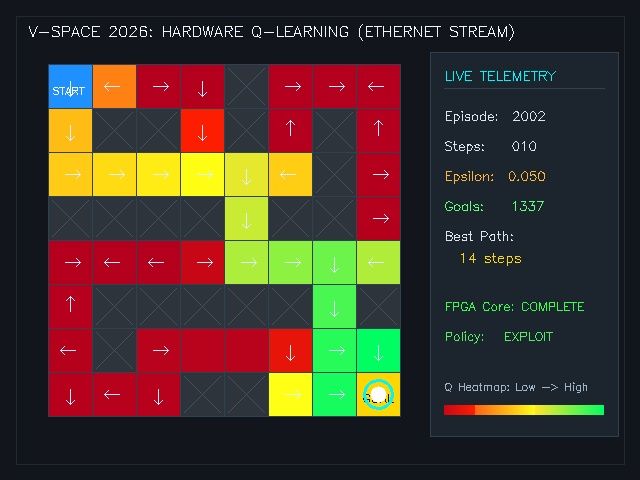

In [4]:
viewer = EthernetVisualizer(agent, fps=12)


status = agent.get_status()
if status['total_goals'] == 0:
    agent.reset()
    agent.configure(alpha=0.10, gamma=0.95, epsilon=0.90, max_episodes=2000)
    agent.start_training(slow_mode=False)
    while not agent.get_status()['done']:
        time.sleep(0.002)


target_ep = agent.get_status()['episode'] + 10
agent.configure(alpha=0.10, gamma=0.95, epsilon=0.00, max_episodes=target_ep, slow_divider=2500000)
agent.start_training(slow_mode=True)

viewer.run_live_stream(duration_sec=8.0)

viewer.close()
st = agent.get_status()
print(f"Goal reached! Total goals: {st['total_goals']}, Shortest path: {st['best_steps']} steps")


In [ ]:
MAZES = {
    'Corridor Detour'  : 0x0010_0055_0000_5500,
    'Center Barrier'   : 0x0000_183C_3C18_0000,
    'Zig-Zag Staircase': 0x4020_9048_2412_0904,
}
original_maze = agent.read_maze()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, layout) in zip(axes, MAZES.items()):
    agent.write_maze(layout)
    agent.reset()
    agent.configure(alpha=0.10, gamma=0.95, epsilon=0.90, max_episodes=1000)
    agent.start_training(slow_mode=False)
    while not agent.get_status()['done']:
        time.sleep(0.005)

    best = agent.get_status()['best_steps']
    values = np.max(agent.read_q_table(), axis=1).reshape((8, 8))
    ax.imshow(values, cmap='magma')
    ax.set_title(f'{name}\nbest path: {best} steps')
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))

plt.suptitle('The same hardware learning three different mazes')
plt.tight_layout()
plt.show()

agent.write_maze(original_maze)                                            
agent.reset()
